# Model comparison, plots and final results (owner: Sriniket Deeduvanu)

In [4]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


,model,val_micro_f1,val_accuracy_percent
0,gradient_boosting,0.727691,72.77
1,neural_network,0.697224,69.72
2,knn,0.680244,68.02
3,random_forest,0.662938,66.29


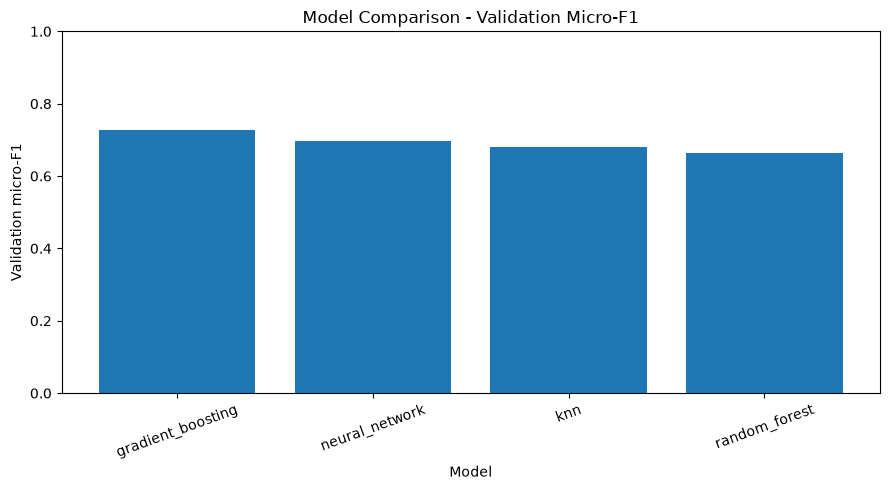

In [5]:

import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

metrics_dir = Path("results/metrics")

# Read only the standard model metric files
model_files = [
    "knn.json",
    "random_forest.json",
    "gradient_boosting.json",
    "neural_network.json",
]

results = []
for filename in model_files:
    file = metrics_dir / filename
    if file.exists():
        with open(file, "r") as f:
            results.append(json.load(f))

comparison_df = pd.DataFrame(results)

if comparison_df.empty:
    print("No saved model metrics found yet.")
else:
    comparison_df = comparison_df.sort_values(
        "val_micro_f1", ascending=False
    ).reset_index(drop=True)

    comparison_df["val_accuracy_percent"] = (
        comparison_df["val_micro_f1"] * 100
    ).round(2)

    display(comparison_df)

    plt.figure(figsize=(9, 5))
    plt.bar(
        comparison_df["model"].astype(str),
        comparison_df["val_micro_f1"]
    )
    plt.ylabel("Validation micro-F1")
    plt.xlabel("Model")
    plt.title("Model Comparison - Validation Micro-F1")
    plt.ylim(0, 1)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(
        "results/figures/model_comparison.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()